Using Colab cache for faster access to the 'heart-failure-clinical-data' dataset.
First five rows:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


Dataset shape (rows, columns): (299, 13)
\nData types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
\nMissing values in each column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
\nDataset information:
<cla

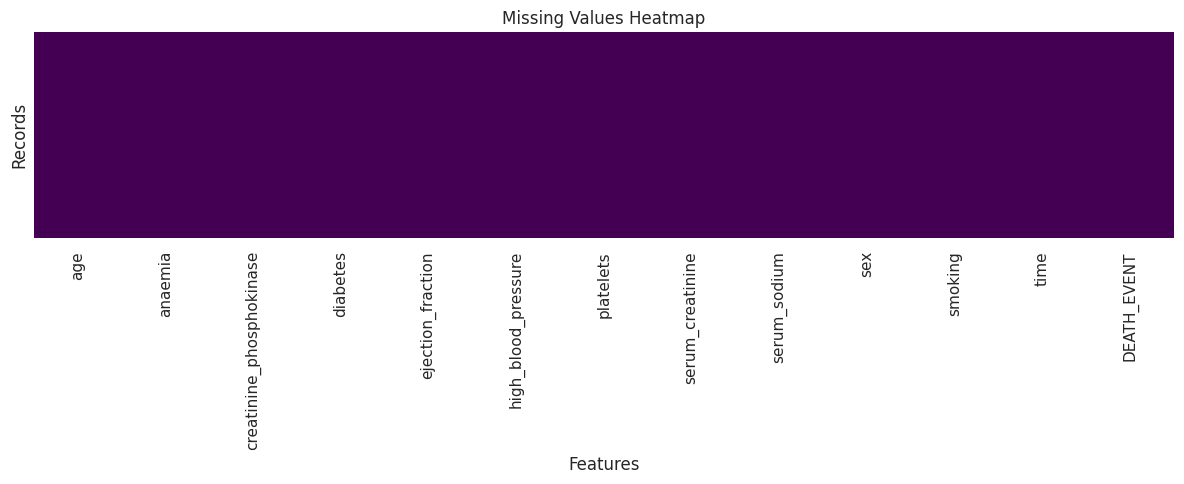

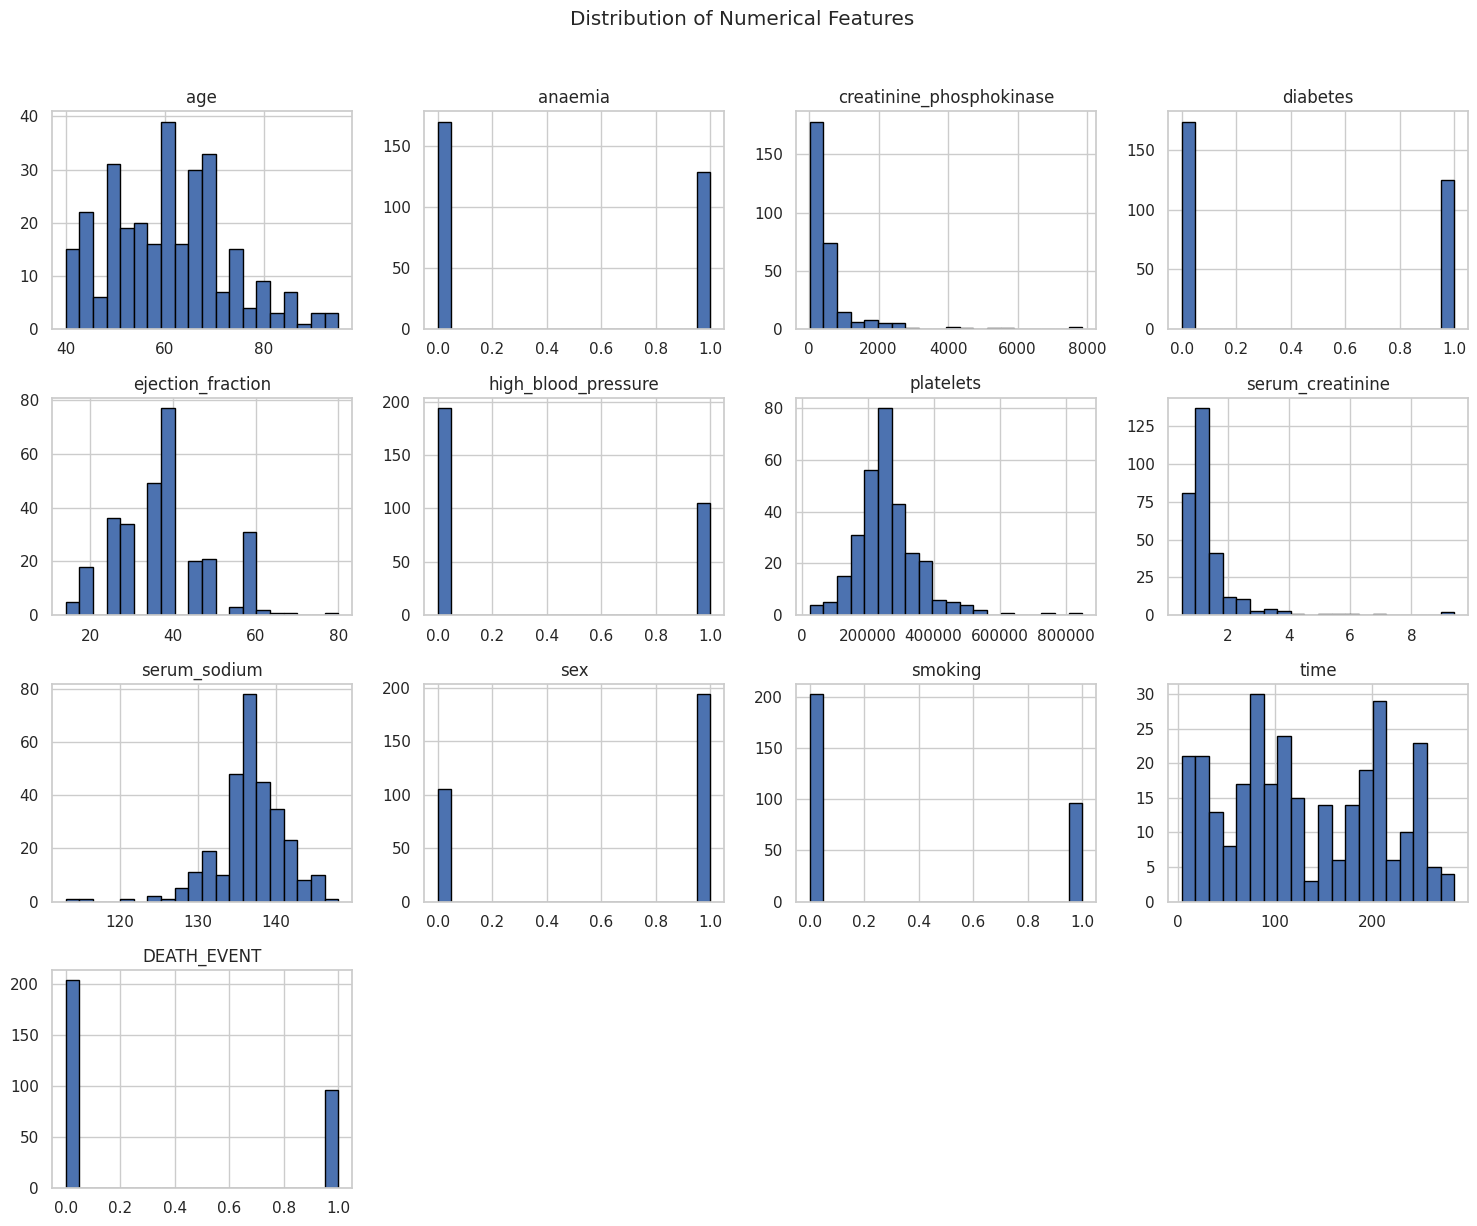

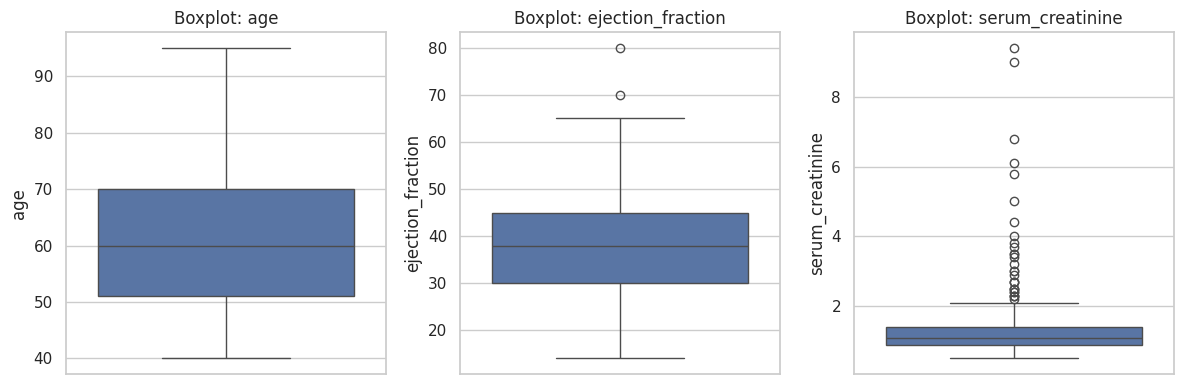

Missing values after imputation:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Rows before outlier removal: 299
Rows after outlier removal:  224
Rows removed:                75
Shape after consistency checks: (224, 13)
Engineered features:


,age,age_group,ejection_fraction,serum_creatinine,risk_score
0,75.0,>60,20,1.9,0.101961
1,65.0,>60,20,1.3,0.054902
2,50.0,40-60,20,1.9,0.101961
3,90.0,>60,40,2.1,0.509804
4,75.0,>60,15,1.2,0.007843


Prepared feature matrix shape: (224, 15)
Target distribution:
DEATH_EVENT
0    163
1     61
Name: count, dtype: int64
Model: Random Forest Classifier
Accuracy: 0.8444
ROC-AUC: 0.9217
\nClassification Report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.90        33
           1       0.73      0.67      0.70        12

    accuracy                           0.84        45
   macro avg       0.80      0.79      0.80        45
weighted avg       0.84      0.84      0.84        45



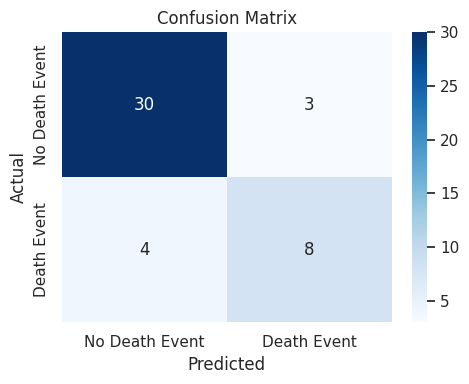

SHAP Summary Plot — impact of features on Death Event prediction


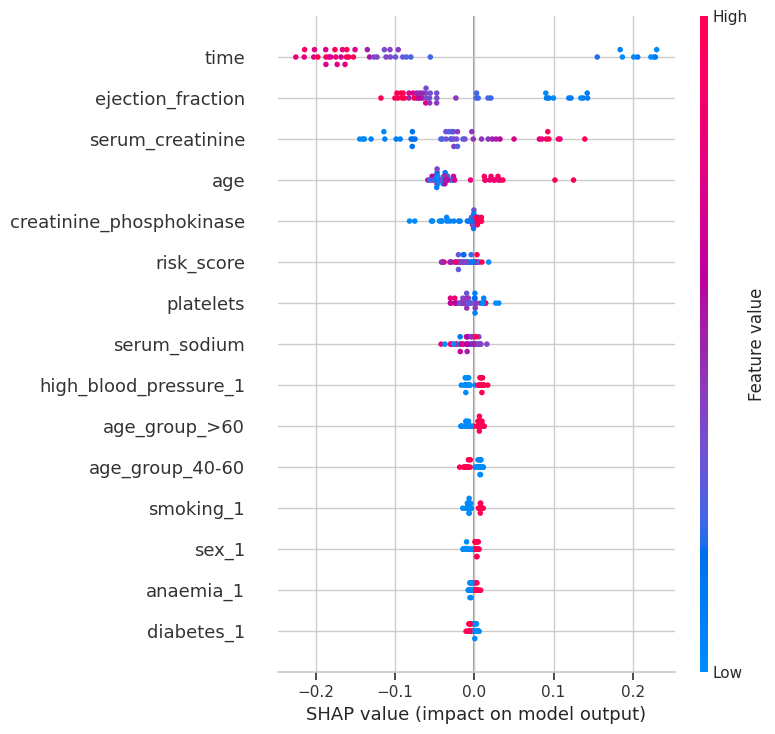

SHAP Feature Importance


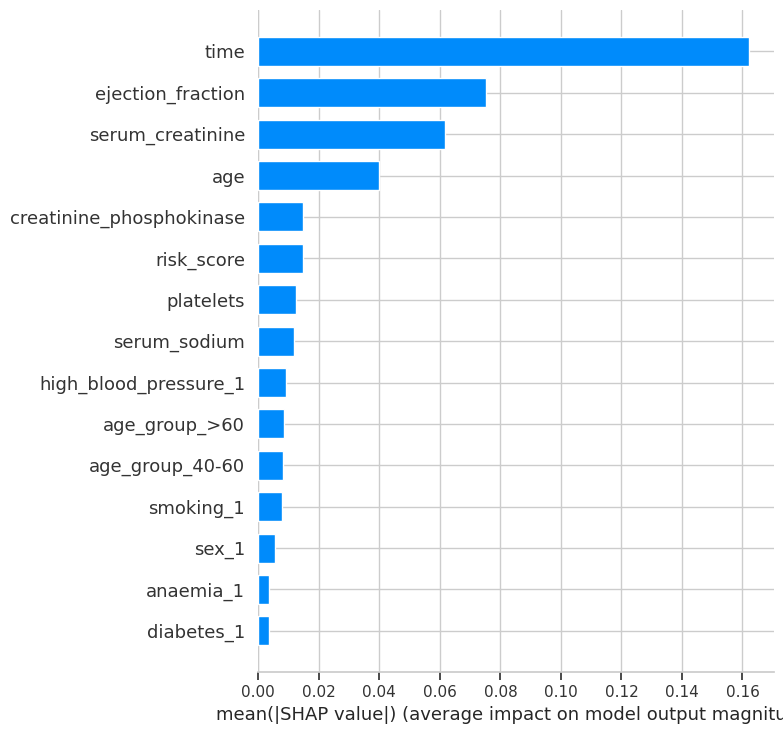

In [1]:

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


# 1. DATASET ACQUISITION


try:
    import kagglehub

    dataset_dir = kagglehub.dataset_download(
        "andrewmvd/heart-failure-clinical-data"
    )
    csv_path = os.path.join(
        dataset_dir, "heart_failure_clinical_records_dataset.csv"
    )
except Exception as error:
    print("Automatic Kaggle download was not successful:", error)
    print("Please download the CSV from Kaggle and place it in this folder.")
    csv_path = "heart_failure_clinical_records_dataset.csv"

if not os.path.exists(csv_path):
    # Colab upload option
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_path = next(
            (name for name in uploaded if name.lower().endswith(".csv")),
            csv_path
        )
    except ImportError:
        pass

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        "CSV file not found. Download heart_failure_clinical_records_dataset.csv "
        "from the Kaggle dataset and place it beside this notebook."
    )



# 2. LOAD DATASET — READ AS DATAFRAME AND DISPLAY FIRST FIVE ROWS

df = pd.read_csv(csv_path)

print("First five rows:")
display(df.head())


# 3. SUMMARIZE DATASET

print("Dataset shape (rows, columns):", df.shape)
print("\\nData types:")
print(df.dtypes)

print("\\nMissing values in each column:")
print(df.isnull().sum())

print("\\nDataset information:")
df.info()


# 4. VISUALIZE MISSING VALUES

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Values Heatmap")
plt.xlabel("Features")
plt.ylabel("Records")
plt.tight_layout()
plt.show()


# 5. PLOT DISTRIBUTIONS OF NUMERICAL FEATURES

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_columns].hist(
    figsize=(15, 12), bins=20, edgecolor="black"
)
plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

features_to_plot = [
    col for col in ["age", "ejection_fraction", "serum_creatinine"]
    if col in df.columns
]
plt.figure(figsize=(12, 4))
for position, column in enumerate(features_to_plot, start=1):
    plt.subplot(1, len(features_to_plot), position)
    sns.boxplot(y=df[column])
    plt.title(f"Boxplot: {column}")
plt.tight_layout()
plt.show()



# 6–8. IMPUTE MISSING VALUES

data = df.copy()

categorical_columns = [
    col for col in [
        "anaemia", "diabetes", "high_blood_pressure",
        "sex", "smoking"
    ] if col in data.columns
]
numerical_columns = [
    col for col in data.select_dtypes(include=np.number).columns
    if col not in categorical_columns
]

for column in numerical_columns:
    if data[column].isnull().any():
        data[column] = data[column].fillna(data[column].median())

for column in categorical_columns:
    if data[column].isnull().any():
        mode_value = data[column].mode()
        fill_value = mode_value.iloc[0] if not mode_value.empty else "Unknown"
        data[column] = data[column].fillna(fill_value)

print("Missing values after imputation:")
print(data.isnull().sum())



# 9. REMOVE OUTLIERS

continuous_columns = [
    col for col in [
        "age", "creatinine_phosphokinase", "ejection_fraction",
        "platelets", "serum_creatinine", "serum_sodium"
    ] if col in data.columns
]

rows_before = len(data)
for column in continuous_columns:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    data = data[
        data[column].between(lower_bound, upper_bound)
    ]

print(f"Rows before outlier removal: {rows_before}")
print(f"Rows after outlier removal:  {len(data)}")
print(f"Rows removed:                {rows_before - len(data)}")



# 10. CORRECT INCONSISTENCIES

if "age" in data.columns:
    data = data[data["age"] >= 0]

non_negative_columns = [
    col for col in [
        "creatinine_phosphokinase", "ejection_fraction",
        "platelets", "serum_creatinine", "serum_sodium", "time"
    ] if col in data.columns
]
for column in non_negative_columns:
    data = data[data[column] >= 0]

# Check binary fields contain only 0 or 1.
binary_columns = [
    col for col in [
        "anaemia", "diabetes", "high_blood_pressure", "sex",
        "smoking", "DEATH_EVENT"
    ] if col in data.columns
]
for column in binary_columns:
    data = data[data[column].isin([0, 1])]

data = data.reset_index(drop=True)
print("Shape after consistency checks:", data.shape)


# 11–13. FEATURE ENGINEERING

data["age_group"] = pd.cut(
    data["age"],
    bins=[-np.inf, 40, 60, np.inf],
    labels=["<40", "40-60", ">60"],
    right=False
)

# Min-max normalize the two values used to form the example risk score.
risk_scaler = MinMaxScaler()
risk_values = risk_scaler.fit_transform(
    data[["ejection_fraction", "serum_creatinine"]]
)
data["risk_score"] = risk_values[:, 0] * risk_values[:, 1]

print("Engineered features:")
display(data[["age", "age_group", "ejection_fraction",
              "serum_creatinine", "risk_score"]].head())



# 14. ENCODE CATEGORICAL VARIABLES

categorical_for_encoding = [
    col for col in [
        "anaemia", "diabetes", "high_blood_pressure",
        "sex", "smoking", "age_group"
    ] if col in data.columns
]

model_data = pd.get_dummies(
    data,
    columns=categorical_for_encoding,
    drop_first=True,
    dtype=int
)



# 15. NORMALIZE NUMERICAL FEATURES TO 0–1 USING MINMAXSCALER

target_column = "DEATH_EVENT"
if target_column not in model_data.columns:
    raise ValueError("Expected target column 'DEATH_EVENT' was not found.")

X = model_data.drop(columns=[target_column])
y = model_data[target_column].astype(int)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
scaler = MinMaxScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])

print("Prepared feature matrix shape:", X.shape)
print("Target distribution:")
print(y.value_counts())


# 16. TRAIN A CLASSIFIER

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    max_depth=5
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print("Model: Random Forest Classifier")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))
print("\\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Death Event", "Death Event"],
    yticklabels=["No Death Event", "Death Event"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()



# 17. EXPLAINABILITY USING SHAP

try:
    import shap

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    # SHAP output format differs across SHAP versions.
    if isinstance(shap_values, list):
        values_for_positive_class = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        values_for_positive_class = shap_values[:, :, 1]
    else:
        values_for_positive_class = shap_values

    print("SHAP Summary Plot — impact of features on Death Event prediction")
    shap.summary_plot(
        values_for_positive_class,
        X_test,
        feature_names=X_test.columns,
        show=True
    )

    print("SHAP Feature Importance")
    shap.summary_plot(
        values_for_positive_class,
        X_test,
        feature_names=X_test.columns,
        plot_type="bar",
        show=True
    )

except ImportError:
    print("SHAP is not installed. Install it using: pip install shap")
except Exception as error:
    print("SHAP could not be displayed in this environment:", error)


